In [11]:
import os
from pathlib import Path
import pickle

import pandas as pd
from sklearn.model_selection import train_test_split
import sklearn.preprocessing
import matplotlib.pyplot as plt
import numpy as np
import torch

In [20]:
scaler = sklearn.preprocessing.QuantileTransformer()
scaler.fit(np.array(torch.load("saved_valacc.pkl"))[..., None])

nb201 = pd.read_csv("nb201_search_eff_allnas.csv")
nb201["representation"] = nb201["representation"].str.strip()
nb201t = pd.read_csv("nb201_search_eff_allnast.csv")
nb201t["representation"] = nb201t["representation"].str.strip()
nb101 = pd.read_csv("nb101_search_eff_allnas.csv")
nb101["representation"] = nb101["representation"].str.strip()
nb101["av_best_acc"] = scaler.inverse_transform(nb101["av_best_acc"].to_numpy()[..., None])[..., 0]
nb101["av_median_acc"] = scaler.inverse_transform(nb101["av_median_acc"].to_numpy()[..., None])[..., 0]
nb101["av_mean_acc"] = scaler.inverse_transform(nb101["av_mean_acc"].to_numpy()[..., None])[..., 0]
nb301 = pd.read_csv("nb301_search_eff_allnas.csv")
nb301["representation"] = nb301["representation"].str.strip()

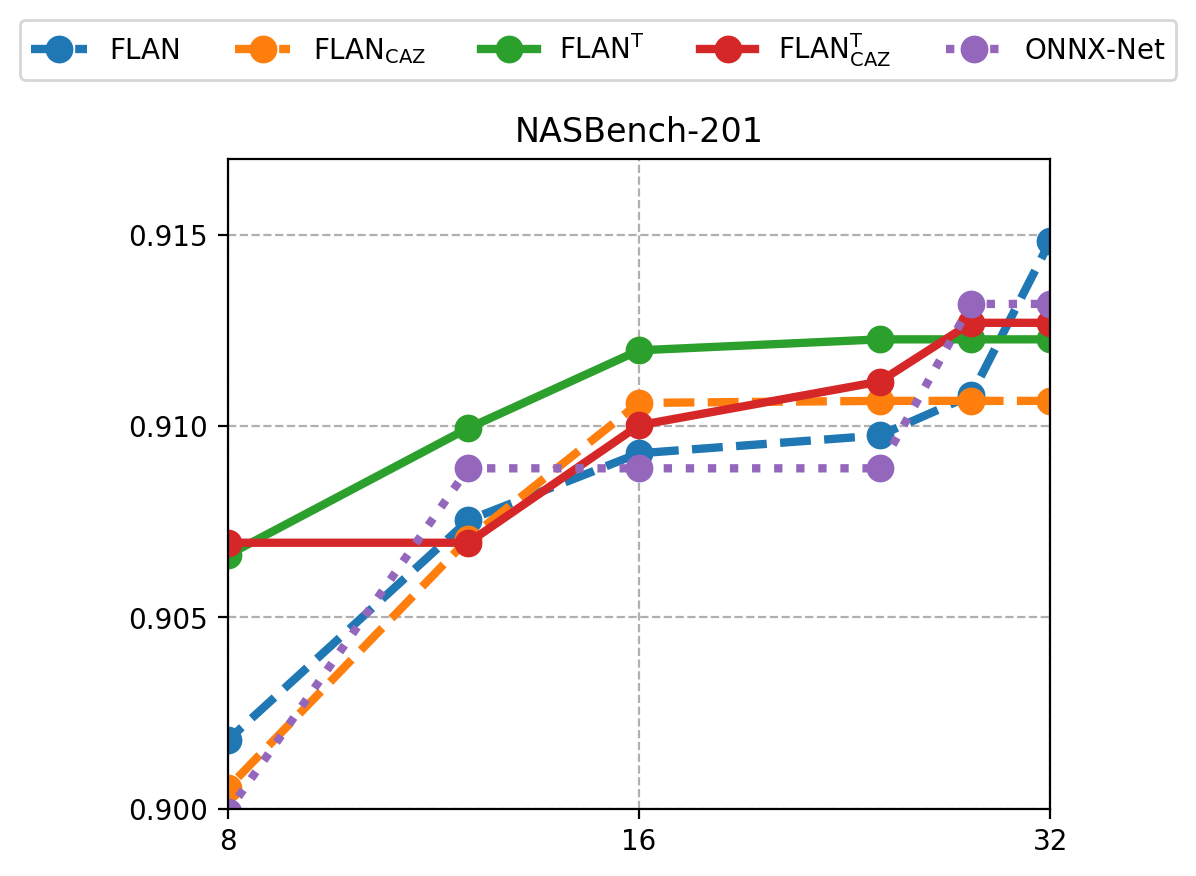

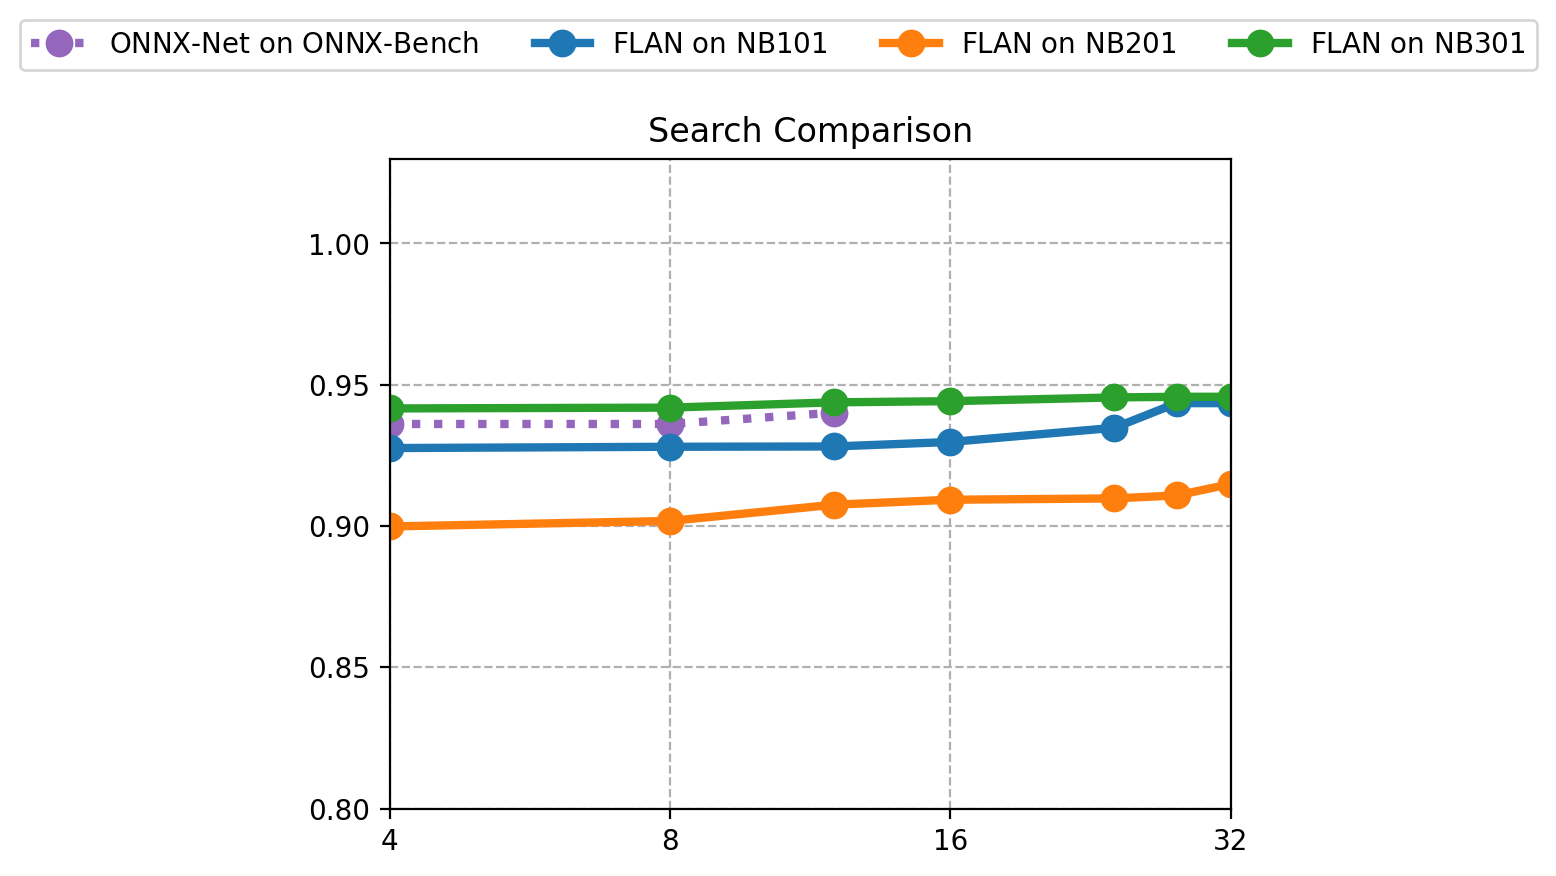

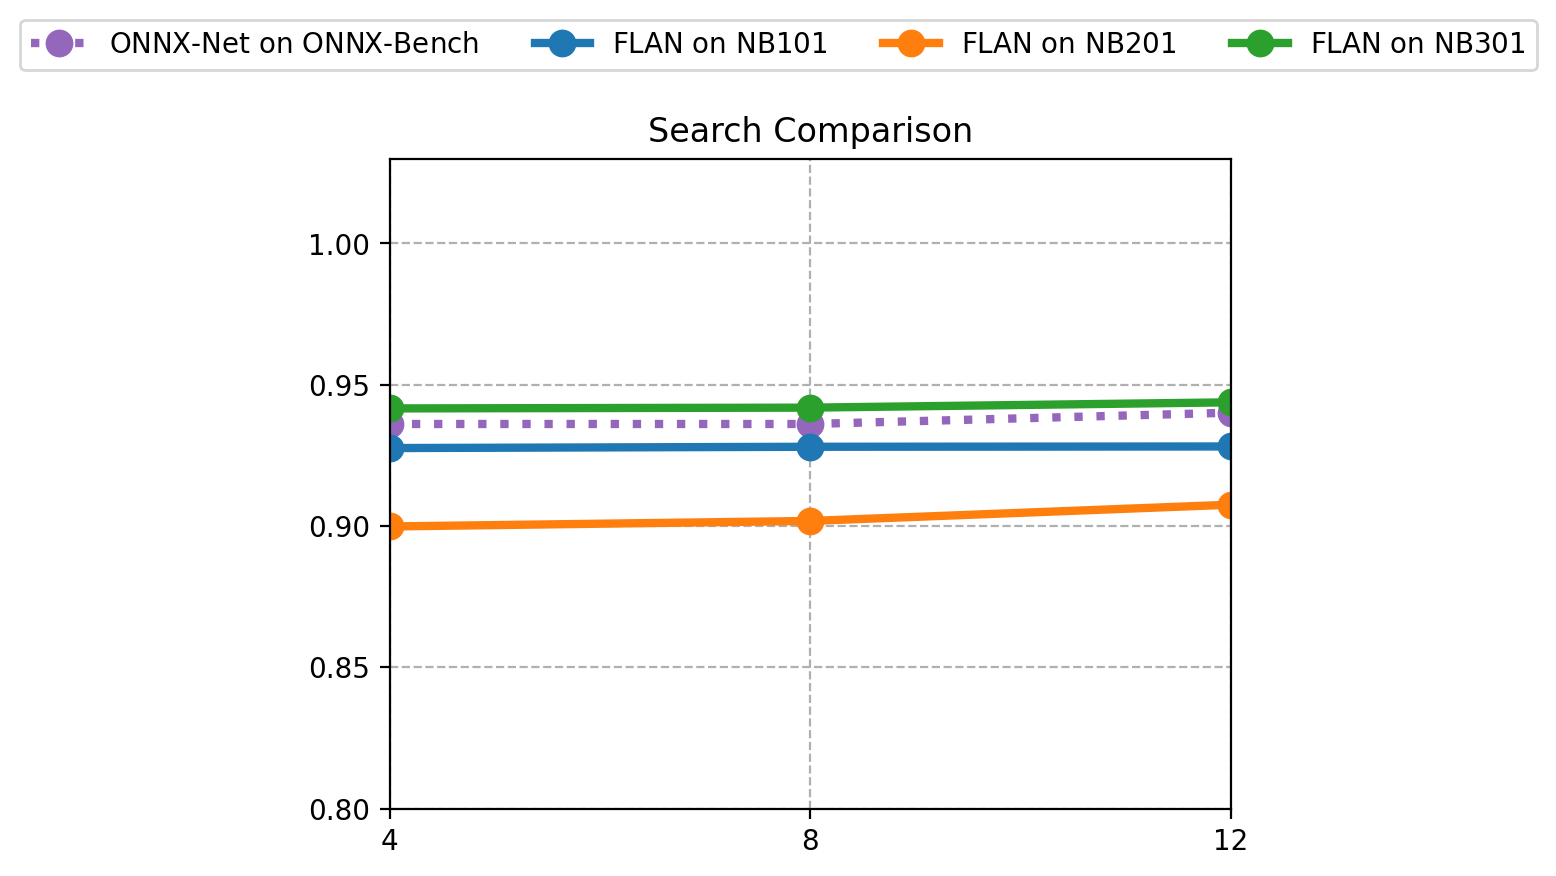

In [21]:
# Select all from flant where representation is adj_gin_zcp
plt.figure(figsize=(5,4), dpi=200)
for rep in ["adj_gin", "adj_gin_a2vcatezcp"]:
    tmp = nb201[nb201["representation"] == rep]
    plt.plot(tmp["num_samps"].tolist(), tmp["av_best_acc"].tolist(), "o--", label={"adj_gin": r"$\text{FLAN}$", "adj_gin_a2vcatezcp": r"$\text{FLAN}_{\text{CAZ}}$"}[rep], color={"adj_gin": "C0", "adj_gin_a2vcatezcp": "C1"}[rep], linewidth=3, markersize=9)
for rep in ["adj_gin", "adj_gin_a2vcatezcp"]:
    tmp = nb201t[nb201t["representation"] == rep]
    plt.plot(tmp["num_samps"].tolist(), tmp["av_best_acc"].tolist(), "o-", label={"adj_gin": r"$\text{FLAN}^\text{T}$", "adj_gin_a2vcatezcp": r"$\text{FLAN}^\text{T}_{\text{CAZ}}$"}[rep], color={"adj_gin": "C2", "adj_gin_a2vcatezcp": "C3"}[rep], linewidth=3, markersize=9)
plt.plot([4, 8, 12, 16, 24, 28, 32], [0.8718, 0.8999, 0.9089, 0.9089, 0.9089, 0.9132, 0.9132], "o:", label=r"$\text{ONNX-Net}$", color="C4", linewidth=3, markersize=9)
plt.xscale("log", base=2)
plt.xticks([8, 16, 32], ['8', '16', '32'])
plt.xlim(8, 32)
plt.yticks(np.arange(0.9, 0.92, 0.005))
plt.ylim(0.9, 0.917)
plt.grid(linestyle="--")
plt.title("NASBench-201")
plt.gcf().legend(loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.1))
plt.tight_layout()
plt.show()

plt.figure(figsize=(5,4), dpi=200)
plt.plot([4, 8, 12], [0.9361, 0.9361, 0.9401], "o:", color="C4", linewidth=3, markersize=9, label=r"$\text{ONNX-Net on ONNX-Bench}$")
plt.xscale("log", base=2)
plt.xticks([4, 8, 16, 32], ["4", '8', '16', '32'])
plt.xlim(4, 32)
plt.yticks(np.arange(0.8, 1.03, 0.05))
plt.ylim(0.8, 1.03)
plt.grid(linestyle="--")
plt.title("Search Comparison")
tmp = nb101[nb101["representation"] == "adj_gin"]
plt.plot(tmp["num_samps"].tolist(), tmp["av_best_acc"].tolist(), "o-", color="C0", label=r"$\text{FLAN on NB101}$", linewidth=3, markersize=9)
tmp = nb201[nb201["representation"] == "adj_gin"]
plt.plot(tmp["num_samps"].tolist(), tmp["av_best_acc"].tolist(), "o-", color="C1", label=r"$\text{FLAN on NB201}$", linewidth=3, markersize=9)
tmp = nb301[nb301["representation"] == "adj_gin"]
plt.plot(tmp["num_samps"].tolist(), [x/100.0 for x in tmp["av_best_acc"].tolist()], "o-", color="C2", label=r"$\text{FLAN on NB301}$", linewidth=3, markersize=9)
plt.gcf().legend(loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.1))
plt.tight_layout()

plt.figure(figsize=(5,4), dpi=200)
plt.plot([4, 8, 12], [0.9361, 0.9361, 0.9401], "o:", color="C4", linewidth=3, markersize=9, label=r"$\text{ONNX-Net on ONNX-Bench}$")
plt.xticks([4, 8, 12], ["4", '8', '12'])
plt.xlim(4, 12)
plt.yticks(np.arange(0.8, 1.03, 0.05))
plt.ylim(0.8, 1.03)
plt.grid(linestyle="--")
plt.title("Search Comparison")
tmp = nb101[nb101["representation"] == "adj_gin"]
plt.plot(tmp["num_samps"].tolist(), tmp["av_best_acc"].tolist(), "o-", color="C0", label=r"$\text{FLAN on NB101}$", linewidth=3, markersize=9)
tmp = nb201[nb201["representation"] == "adj_gin"]
plt.plot(tmp["num_samps"].tolist(), tmp["av_best_acc"].tolist(), "o-", color="C1", label=r"$\text{FLAN on NB201}$", linewidth=3, markersize=9)
tmp = nb301[nb301["representation"] == "adj_gin"]
plt.plot(tmp["num_samps"].tolist(), [x/100.0 for x in tmp["av_best_acc"].tolist()], "o-", color="C2", label=r"$\text{FLAN on NB301}$", linewidth=3, markersize=9)
plt.gcf().legend(loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.1))
plt.tight_layout()
pass

Performance of a sampling based neural architecture search using FLAN and ONNX-Net on NASBench-201.

Performance of a neural architecture search using ONNX-Net on ONNX-Bench. For comparison the performance of FLAN on the different NASBench search-spaces is also shown.

In [38]:
source_path = Path("./data/chain_slim_v1")
target_path = Path("./data/chain_slim_v1")

In [39]:
data = None
for name in ["einspace_augmentation", "hnasbench201", "nasbench101_val", "nasbench201", "nasbench301", "natsbench", "transnasbench101"]:
    if data is None:
        data = pd.read_csv(source_path.joinpath(name).with_suffix(".csv"))
    else:
        data = pd.concat([data, pd.read_csv(source_path.joinpath(name).with_suffix(".csv"))])

In [48]:
data[~data.onnx_encoding.isna()].to_csv(target_path.joinpath("onnxbench.csv"), index=False)

In [ ]:
# for entry in data.itertuples():
#     if type(entry.onnx_encoding) != str:
#         print("Enc", entry.Index, entry.onnx_encoding)

Enc 440 nan
Enc 899 nan
Enc 1222 nan
Enc 2472 nan
Enc 3281 nan
Enc 3597 nan
Enc 4690 nan
Enc 6810 nan
Enc 7185 nan
Enc 8166 nan
Enc 8935 nan
Enc 9281 nan
Enc 10659 nan
Enc 12201 nan
Enc 14120 nan
Enc 14195 nan
Enc 14713 nan
Enc 15864 nan
Enc 16464 nan
Enc 16676 nan
Enc 17682 nan
Enc 17936 nan
Enc 18061 nan
Enc 18150 nan
Enc 19162 nan
Enc 20114 nan
Enc 20984 nan
Enc 21627 nan
Enc 22336 nan
Enc 23582 nan
Enc 23585 nan
Enc 24025 nan
Enc 24360 nan
Enc 24539 nan
Enc 25769 nan
Enc 26139 nan
Enc 29940 nan
Enc 30309 nan
Enc 31823 nan
Enc 32568 nan
Enc 32621 nan
Enc 34284 nan
Enc 34413 nan
Enc 34637 nan
Enc 35079 nan
Enc 35322 nan
Enc 35465 nan
Enc 36013 nan
Enc 36076 nan
Enc 36433 nan
Enc 36504 nan
Enc 36835 nan
Enc 36931 nan
Enc 36944 nan
Enc 37395 nan
Enc 38613 nan


#### Prepare einspace data
- split by seed

In [1]:
einspace = pd.read_csv(os.path.join(source_path, "einspace.csv"))
einspace_aug = pd.read_csv(os.path.join(source_path, "einspace_augmentation.csv"))

NameError: name 'pd' is not defined

In [ ]:
einspace.columns

In [ ]:
einspace["seed"] = einspace["name"].apply(lambda x: x.split("_")[0])

In [ ]:
einspace_val = einspace[einspace["seed"] == "seed=4"]
einspace_train = einspace[(einspace["seed"] != "seed=4") & (einspace["seed"] != "seed=0")]

In [ ]:
einspace_train = pd.concat([einspace_train, einspace_aug], ignore_index=True)
einspace_train = einspace_train[einspace_train["accuracy"] > 2]

In [ ]:
print("Training set shape:", einspace_train.shape)
print("Validation set shape:", einspace_val.shape)

In [ ]:
einspace_train.to_csv(os.path.join(target_path, "einspace_train.csv"), index=False)
einspace_val.to_csv(os.path.join(target_path, "einspace_val.csv"), index=False)

#### Prepare hnasbench201 data
- split by seed

In [ ]:
hnasbench201 = pd.read_csv(source_path / "hnasbench201.csv")

In [ ]:
hnasbench201["seed"] = hnasbench201["name"].apply(lambda x: x.split("_")[0])
hnasbench201["index"] = hnasbench201["name"].apply(lambda x: x.split("_")[1])

In [ ]:
hnasbench201_val = hnasbench201[hnasbench201["seed"] == "seed=4"]
hnasbench201_train = hnasbench201[hnasbench201["seed"] != "seed=4"]
hnasbench201_train = hnasbench201_train[hnasbench201_train["accuracy"] > 2]

In [ ]:
print("Training set shape:", hnasbench201_train.shape)
print("Validation set shape:", hnasbench201_val.shape)

Training set shape: (6403, 7)
Validation set shape: (1000, 7)


In [ ]:
hnasbench201_train.to_csv(target_path / "hnasbench201_train.csv", index=False)
hnasbench201_val.to_csv(target_path / "hnasbench201_val.csv", index=False)

#### Prepare nasbench201 + natsbench data
- these two search space considered together
- random split by 80%/20%

In [ ]:
nasbench201 = pd.read_csv(source_path / "nasbench201.csv")
natsbench = pd.read_csv(source_path / "natsbench.csv")

In [ ]:
nas201nats = pd.concat([nasbench201, natsbench], ignore_index=True)
nas201nats_train, nas201nats_val = train_test_split(nas201nats, test_size=0.2, random_state=42)

In [ ]:
print("Training set shape:", nas201nats_train.shape)
print("Validation set shape:", nas201nats_val.shape)

Training set shape: (38714, 5)
Validation set shape: (9679, 5)


In [ ]:
nas201nats_train.to_csv(target_path / "nas201nats_train.csv", index=False)
nas201nats_val.to_csv(target_path / "nas201nats_val.csv", index=False)

#### Prepare nasbench101
- split based on hash file

In [ ]:
with Path("data/nb101_hash.txt").open("rb") as fp:
    nb101_hash = pickle.load(fp)
nasbench101 = pd.read_csv(source_path / "nasbench101.csv")

In [ ]:
nasbench101["hash"] = nasbench101["name"].apply(lambda x: x.split("_")[-1])

In [ ]:
nasbench101_val = nasbench101[nasbench101["hash"].isin(nb101_hash)]
nasbench101_train = nasbench101[~nasbench101["hash"].isin(nb101_hash)]

In [ ]:
print("Training set shape:", nasbench101_train.shape)
print("Validation set shape:", nasbench101_val.shape)

Training set shape: (416334, 6)
Validation set shape: (7290, 6)


In [ ]:
nasbench101_train.to_csv(target_path / "nasbench101_train.csv", index=False)
nasbench101_val.to_csv(target_path / "nasbench101_val.csv", index=False)

In [ ]:
nasbench101_train = nasbench101_train.sample(n = 50_000, random_state=42).reset_index(drop=True)
nasbench101_train.to_csv(target_path / "nasbench101_50k.csv", index=False)

#### Prepare nasbench301
- split based on source

In [ ]:
nasbench301 = pd.read_csv(source_path / "nasbench301.csv")

In [ ]:
def list_onnx_files(folder_path: Path) -> list[Path]:
    """
    Return a list of all .onnx file paths found within `folder_path` (recursively).
    """
    onnx_files = []
    for root, dirs, files in os.walk(str(folder_path)):
        for file in files:
            if file.lower().endswith(".onnx"):
                full_path = Path(root) / Path(file)
                onnx_files.append(full_path)
    return onnx_files

onnx_files = list_onnx_files(Path("./data/nasbench301_simplify"))

In [ ]:
index_source_map = {}
for i in onnx_files:
    index = i.stem
    source = i.parent.name
    index_source_map[index] = source

In [ ]:
nasbench301["source"] = nasbench301["name"].apply(lambda x: index_source_map[str(x)])

In [ ]:
val_sources = ["only_avg_pool_3x3", "local_search", "bananas"]

In [ ]:
nasbench301_train = nasbench301[~nasbench301["source"].isin(val_sources)]
nasbench301_val = nasbench301[nasbench301["source"].isin(val_sources)]

In [ ]:
print("Training set shape:", nasbench301_train.shape)
print("Validation set shape:", nasbench301_val.shape)

Training set shape: (57188, 6)
Validation set shape: (0, 6)


In [ ]:
nasbench301_train.to_csv(target_path / "nasbench301_train.csv", index=False)
nasbench301_val.to_csv(target_path / "nasbench301_val.csv", index=False)